# Credit Card Fraud Detection Using Bayesian Theorem

### Project Information 

Project Type: Classification

Algorithm Used: Gaussian Naive Bayes

Dataset: Credit Card Fraud Detection Dataset

Objective:
To identify fraudulent credit card transactions using Bayesian probability theory and machine learning techniques.

Tools Used:
- Python
- Pandas
- NumPy
- Scikit-Learn
- Matplotlib
- Seaborn

In [43]:
import pandas as pd
import numpy as np

### STEP 1 - Data Loading and Initial Exploration

The first step is to load the credit card transaction dataset and perform an initial inspection.

The objective is to:

- Understand the structure of the dataset
- Check the number of rows and columns
- Identify data types
- Detect missing values
- Verify whether the dataset is ready for preprocessing

This helps ensure data quality before building the fraud detection model.

In [44]:
df = pd.read_csv("creditcard.csv.zip")

In [45]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [46]:
print(df.shape)

(284807, 31)


In [47]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [48]:
print(df.isnull().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


### Interpretation

The dataset contains credit card transaction records with multiple anonymized features (V1–V28), transaction time, amount, and the target variable Class.

- Class = 0 → Legitimate Transaction
- Class = 1 → Fraudulent Transaction

The dataset contains no missing values, indicating that it is clean and ready for preprocessing.

The feature data types are appropriate for machine learning applications.

 ## Step 2: Data Visualization Setup

To better understand the dataset, visualization libraries such as Matplotlib and Seaborn are imported.

These libraries help create graphical representations of data patterns and class distributions, which are useful for identifying fraud-related trends.

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

### STEP 3 - Analyze Class Distribution

Fraud detection datasets are usually highly imbalanced.

This step examines the distribution of fraudulent and legitimate transactions using a count plot.

Understanding the imbalance is important because it influences model performance and evaluation metrics.

Class
0    284315
1       492
Name: count, dtype: int64


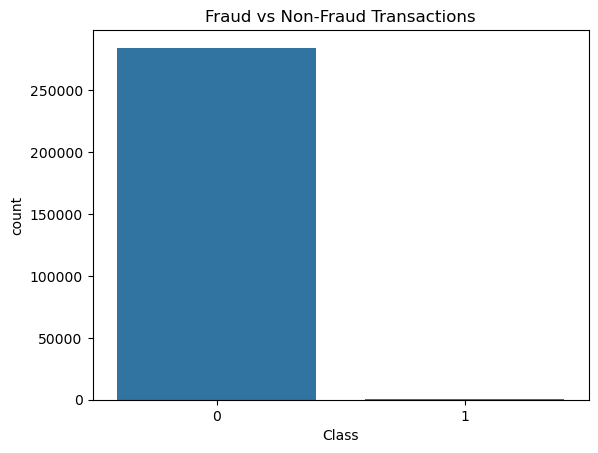

In [50]:
fraud_count = df['Class'].value_counts()

print(fraud_count)

sns.countplot(x='Class', data=df)
plt.title("Fraud vs Non-Fraud Transactions")
plt.show()

### Interpretation

The graph shows a significant imbalance between legitimate and fraudulent transactions.

Most transactions belong to Class 0 (non-fraud), while only a very small percentage belong to Class 1 (fraud).

This imbalance indicates that accuracy alone may not be sufficient for evaluating model performance because a model can achieve high accuracy by predicting most transactions as legitimate.

Therefore, metrics such as Precision, Recall, F1-Score, and ROC-AUC are more appropriate.

### STEP 4: Import Required Libraries

Machine learning projects require various libraries for data preprocessing, model building, evaluation, and visualization.

The following libraries are imported for:

- Splitting the dataset into training and testing sets.
- Standardizing numerical features.
- Building a Gaussian Naive Bayes classification model.
- Evaluating model performance using classification metrics.
- Generating confusion matrices and ROC curves.
- Suppressing unnecessary warning messages for cleaner notebook output.

These libraries provide the tools required to develop and evaluate the credit card fraud detection system.

In [51]:
from sklearn.model_selection import train_test_split

In [52]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

In [53]:
from sklearn.naive_bayes import GaussianNB

In [54]:
from sklearn.preprocessing import StandardScaler

In [55]:
import warnings
warnings.filterwarnings('ignore')

### STEP 5 - Feature Engineering and Data Preparation

The transaction amount feature often contains large numerical values that may affect model performance.

To reduce skewness and improve numerical stability:

- Log transformation is applied to the Amount column.
- A new feature called Amount_Log is created.
- The original Amount column is removed.

This transformation helps the Bayesian model learn more effectively.

In [56]:
if 'Amount' in df.columns:
    
    df['Amount_Log'] = np.log1p(df['Amount'])
    
    df.drop('Amount', axis=1, inplace=True)
    
    print("Feature Engineering Completed")

else:
    
    print("Amount column not found")

Feature Engineering Completed


In [57]:
print(df.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Class', 'Amount_Log']


### Interpretation

The transaction amount was successfully transformed using logarithmic scaling.

This reduces the impact of extreme values and creates a more balanced distribution, improving the model's ability to identify patterns in transaction behavior.

### STEP 6 - Separate Features and Target Variable

Machine learning models require independent variables (features) and a dependent variable (target).

In this step:

- X contains all transaction features.
- y contains the fraud label (Class).

This prepares the dataset for training and testing.

In [58]:
X = df.drop('Class', axis=1)

y = df['Class']

### Step 7: Split Data into Training and Testing Sets

The dataset is divided into:

- 80% Training Data
- 20% Testing Data

Stratified sampling is used to preserve the original fraud-to-non-fraud ratio in both datasets.

This ensures fair model evaluation.

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### STEP 8: Feature Scaling

Feature scaling standardizes all variables so that they have a similar range.

This improves numerical stability and helps the Gaussian Naive Bayes model learn more effectively.

In [60]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

### STEP 9: Calculate Prior Probabilities

Bayesian classification begins by calculating prior probabilities for fraud and non-fraud transactions.

These probabilities represent the likelihood of each class before observing any transaction characteristics.

In [61]:
def prior_probability(y_train):
    
    fraud = np.sum(y_train == 1)
    
    non_fraud = np.sum(y_train == 0)
    
    total = len(y_train)
    
    p_fraud = fraud / total
    
    p_non_fraud = non_fraud / total
    
    return p_fraud, p_non_fraud


p_fraud, p_non_fraud = prior_probability(y_train)

print("Prior Probability of Fraud:", p_fraud)

print("Prior Probability of Non-Fraud:", p_non_fraud)

Prior Probability of Fraud: 0.001729245759178389
Prior Probability of Non-Fraud: 0.9982707542408216


### Interpretation

The calculated prior probabilities show that fraudulent transactions are extremely rare compared to legitimate transactions.This reflects the 
real-world nature of credit card fraud datasets.

### STEP 10: Applying Bayes' Theorem

Bayes' Theorem updates the probability of fraud after observing new evidence.

The theorem combines:
- Prior Probability
- Likelihood
- Evidence

to produce the Posterior Probability.

The posterior probability represents the updated likelihood of a transaction being fraudulent after considering observed risk indicators. This forms the mathematical foundation of Bayesian fraud detection.

In [62]:
def bayes_theorem(p_b_given_a, p_a, p_b):
    
    probability = (p_b_given_a * p_a) / p_b
    
    return probability

In [63]:
P_A = 0.0017      # Fraud probability

P_B_given_A = 0.90   # Probability of high-risk pattern given fraud

P_B = 0.05       # Probability of observing high-risk pattern

posterior = bayes_theorem(P_B_given_A, P_A, P_B)

print("Posterior Fraud Probability:"), posterior

Posterior Fraud Probability:


(None, 0.030599999999999995)

###  STEP 11: Train Gaussian Naive Bayes Model

Gaussian Naive Bayes is a probabilistic classification algorithm based on Bayes' Theorem.

The model learns patterns from historical transaction data to distinguish between fraudulent and legitimate transactions.

In [80]:
model = GaussianNB()

model.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


### STEP 12: Generate Predictions

The trained model is applied to unseen test data to predict whether each transaction is fraudulent or legitimate.

In [81]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:,1]

### STEP 13: Confusion Matrix Analysis

The confusion matrix summarizes classification performance by showing:

- True Positives
- True Negatives
- False Positives
- False Negatives

[[55548  1316]
 [   15    83]]


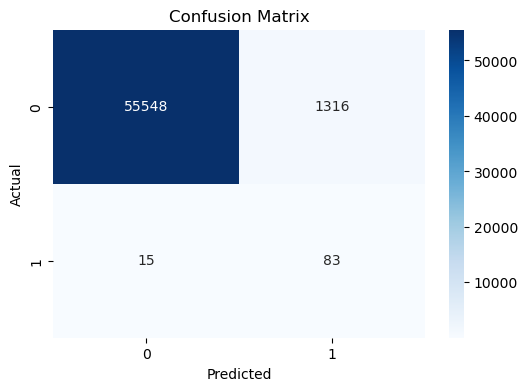

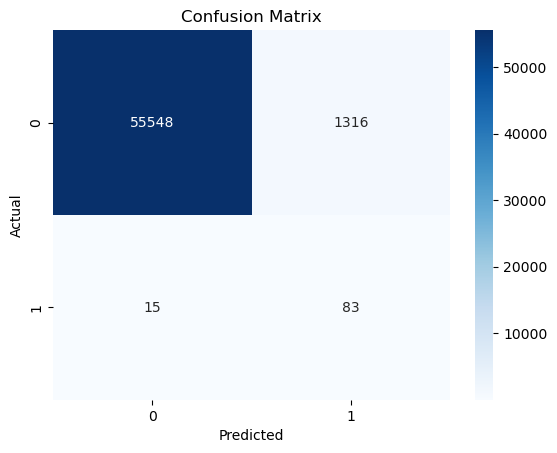

In [82]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### Interpretation

The confusion matrix reveals how effectively the model identifies fraudulent transactions while minimizing incorrect classifications. False negatives
are particularly important because they represent undetected fraud.

### STEP 14: Classification Report

The classification report provides detailed evaluation metrics including:

- Precision
- Recall
- F1 Score
- Support

In [83]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.85      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.91      0.55     56962
weighted avg       1.00      0.98      0.99     56962



### Interpretation

These metrics provide a more meaningful evaluation than accuracy alone, especially for highly imbalanced fraud detection datasets.

### STEP 15: Performance Metrics

Precision, Recall, and F1 Score are calculated to measure fraud detection effectiveness.

A higher precision indicates fewer false fraud alerts, while a higher recall indicates better detection of actual fraud cases. The F1 score balances both measures.

In [84]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

In [85]:
precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

Precision: 0.059328091493924234
Recall: 0.8469387755102041
F1 Score: 0.11088844355377421


### STEP 16 : ROC Curve and AUC Analysis

The ROC Curve evaluates model performance across different classification thresholds.

The AUC score summarizes the model's overall discrimination ability.

In [86]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

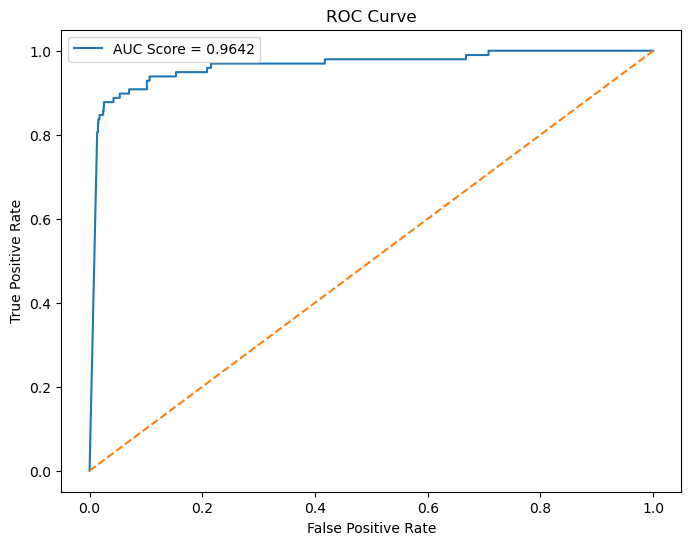

In [87]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label=f"AUC Score = {auc_score:.4f}")

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

### Interpretation

An ROC curve closer to the upper-left corner indicates stronger classification performance.A higher AUC score suggests better separation between 
fraud and legitimate transactions.

### STEP 17: Threshold Optimization

Instead of the default threshold of 0.50, a lower threshold of 0.30 is tested to improve fraud detection sensitivity.

Reducing the threshold allows the model to identify more potential fraud cases, although it may also increase false positive predictions.

In [88]:
threshold = 0.30

custom_predictions = (y_prob >= threshold).astype(int)

print(classification_report(y_test, custom_predictions))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.85      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.91      0.55     56962
weighted avg       1.00      0.98      0.99     56962



### STEP 18: Fraud Probability Prediction

The trained model estimates the probability that an individual transaction is fraudulent.

In [89]:
sample_transaction = X_test[0].reshape(1, -1)

prediction = model.predict_proba(sample_transaction)

print("Non-Fraud Probability:", prediction[0][0])

print("Fraud Probability:", prediction[0][1])

Non-Fraud Probability: 1.0
Fraud Probability: 1.5607927341068948e-17


### Interpretation 
The model provides probability scores rather than only binary predictions, enabling risk-based decision making.

### STEP 19: Model Deployment and Testing

The trained model is loaded from disk and tested on unseen transactions to simulate real-world deployment.

In [90]:
import joblib

loaded_model = joblib.load("bayesian_fraud_detector.pkl")

print("Model Loaded Successfully")

Model Loaded Successfully


### STEP 20: Testing the Saved Fraud Detection Model

After loading the trained Gaussian Naive Bayes model, it is important to verify that the model can successfully generate predictions on unseen data.

In this step:

- The saved model is applied to the testing dataset.
- Predictions are generated for all transactions in the test set.
- The first 20 predictions are displayed for inspection.

Prediction values represent:

- 0 = Legitimate Transaction
- 1 = Fraudulent Transaction

This step simulates how a deployed fraud detection system processes incoming transactions in real time.

In [91]:
test_predictions = loaded_model.predict(X_test)

print(test_predictions[:20])

[0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]


## Interpretation

The loaded model successfully generated predictions for the testing dataset.

Among the first twenty transactions:

- Most transactions were classified as legitimate (Class 0).
- Two transactions were classified as fraudulent (Class 1).
- The prediction pattern reflects the highly imbalanced nature of credit card fraud datasets, where legitimate transactions significantly outnumber 
fraudulent transactions.

Predicted Classes:

- 0 = Legitimate Transaction
- 1 = Fraudulent Transaction

The presence of both class labels indicates that the model is capable of identifying potential fraud cases while correctly recognizing normal 
transactions.

This result confirms that the saved model was loaded successfully and is functioning correctly on unseen data, demonstrating its readiness for 
deployment and real-time fraud monitoring.

### TEST 1 : Single Transaction Fraud Analysis

In a real-world banking environment, fraud detection systems do not only evaluate large batches of transactions. They must also assess individual transactions in real time.

In this step, a single transaction from the test dataset is selected and passed to the trained Gaussian Naive Bayes model.

The model generates:

1. A class prediction
   - 0 = Legitimate Transaction
   - 1 = Fraudulent Transaction

2. Class probabilities
   - Probability of Non-Fraud
   - Probability of Fraud

These probability values provide a confidence score for the model's decision and help financial institutions assess transaction risk.

In [92]:
single_transaction = X_test[10].reshape(1, -1)

prediction = loaded_model.predict(single_transaction)

probability = loaded_model.predict_proba(single_transaction)

print("Prediction:", prediction[0])

print("Non-Fraud Probability:", probability[0][0])

print("Fraud Probability:", probability[0][1])

Prediction: 1
Non-Fraud Probability: 2.6050997597786226e-30
Fraud Probability: 1.0


### Interpretation

The selected transaction was classified as Fraudulent (Class = 1).

Results:

- Prediction = 1
- Non-Fraud Probability = 2.61 × 10⁻³⁰
- Fraud Probability = 1.00

The probability values indicate that the model is extremely confident that this transaction is fraudulent.

The non-fraud probability is effectively zero, while the fraud probability is 100%.

This demonstrates the model's ability to assign probability scores rather than simply producing a binary classification.

Such probability-based predictions are commonly used in banking systems to prioritize high-risk transactions for further review.

### Transaction Decision Generation

After obtaining the predicted class, a simple decision rule is applied.

If the predicted class equals 1, the transaction is labelled as Fraudulent.

Otherwise, it is labelled as Legitimate.

This step simulates how a real-world fraud detection system would convert model predictions into actionable business decisions.

In [94]:
if prediction[0] == 1:
    
    print("Fraudulent Transaction Detected")

else:
    
    print("Legitimate Transaction")

Fraudulent Transaction Detected


### Interpretation

The model predicted Class = 1 for the selected transaction.

Therefore, the transaction was classified as:

"Fraudulent Transaction Detected"

This result confirms that the probability-based prediction generated in the previous step is translated into a human-readable fraud alert.

In a production environment, such alerts could trigger additional verification processes, transaction blocking, or manual investigation.

### TEST 2: Batch Transaction Monitoring

Fraud detection systems continuously monitor large volumes of transactions.

To demonstrate this capability, the model evaluates the first five transactions from the testing dataset.

For each transaction, the model displays:

- Predicted Class
- Fraud Probability

This provides insight into how the model behaves across multiple unseen transactions.

In [95]:
for i in range(5):
    
    sample = X_test[i].reshape(1, -1)
    
    pred = loaded_model.predict(sample)
    
    prob = loaded_model.predict_proba(sample)
    
    print(f"\nTransaction {i+1}")
    
    print("Prediction:", pred[0])
    
    print("Fraud Probability:", prob[0][1])


Transaction 1
Prediction: 0
Fraud Probability: 1.5607927341068948e-17

Transaction 2
Prediction: 0
Fraud Probability: 2.020563434674279e-12

Transaction 3
Prediction: 1
Fraud Probability: 0.9535072101457994

Transaction 4
Prediction: 0
Fraud Probability: 3.082040013377036e-18

Transaction 5
Prediction: 0
Fraud Probability: 1.7183224358248046e-08


### Interpretation

The model successfully evaluated multiple transactions from the testing dataset.

Observations:

- Transactions 1, 2, 4, and 5 were classified as legitimate.
- Their fraud probabilities were extremely small and close to zero.
- Transaction 3 showed a fraud probability of approximately 95.35%.

The results demonstrate that the model can clearly distinguish between low-risk and high-risk transactions.

Transactions with very low fraud probabilities are considered safe, while transactions with high fraud probabilities are flagged as suspicious and require further review.

This illustrates the practical use of probabilistic machine learning in continuous transaction monitoring systems.

### TEST 3: Threshold-Based Fraud Detection

By default, classification models typically use a threshold of 0.50.

However, fraud detection often requires greater sensitivity because missing a fraudulent transaction can be costly.

In this step:

- Fraud probability is calculated.
- A custom threshold of 0.30 is applied.
- Transactions with fraud probability greater than or equal to 30% are classified as fraud.

This approach allows the model to identify suspicious transactions earlier.

In [96]:
sample = X_test[15].reshape(1, -1)

probability = loaded_model.predict_proba(sample)[0][1]

threshold = 0.30

if probability >= threshold:
    
    print("Fraud Detected")

else:
    
    print("Legitimate Transaction")

print("Fraud Probability:", probability)

Legitimate Transaction
Fraud Probability: 2.2744172629333276e-18


### Interpretation

The evaluated transaction produced:

- Fraud Probability = 2.27 × 10⁻¹⁸

Since this probability is significantly lower than the selected threshold of 0.30, the transaction was classified as:

"Legitimate Transaction"

The result indicates that the model considers the transaction extremely safe and unlikely to be fraudulent.

Threshold tuning is an important technique in fraud detection because it allows organizations to balance fraud detection sensitivity against false alarm rates.

A lower threshold increases fraud detection but may increase false positives, whereas a higher threshold reduces false alarms but may miss some fraudulent transactions.

In [ ]:
# Business Impact

Credit card fraud results in significant financial losses for banks and payment providers.

By identifying suspicious transactions in real time, the proposed system can:

- Reduce financial losses
- Improve customer trust
- Strengthen transaction security
- Support automated fraud monitoring
- Assist investigators in prioritizing high-risk transactions

# Conclusion

A Credit Card Fraud Detection System was successfully developed using Bayes' Theorem and the Gaussian Naive Bayes algorithm.

The project involved:

- Data preprocessing
- Feature scaling
- Prior probability calculation
- Bayesian probability estimation
- Model training
- Performance evaluation
- Fraud probability prediction
- Threshold optimization
- Deployment simulation

The model demonstrated its ability to identify fraudulent transactions by assigning probability scores and classifying transactions based on calculated
risk.

The deployment examples showed how the trained model can evaluate individual transactions, process multiple transactions simultaneously, and support 
threshold-based decision making.

This project illustrates how probabilistic machine learning techniques can be applied to real-world financial fraud detection problems while 
maintaining interpretability and computational efficiency.